# Intro

* How to incorporate dropout into a multiple parts of an LLM
* How to toggle dropout in the attention algorithm for evaluation
* The importance of training set variability for training performance

# FineWebb Dataset

In [ ]:
!pip install datatrove
!pip install --upgrade "huggingface-hub<1.0,>=0.24.0" "transformers<4.45.0" datatrove
from datatrove.pipeline.readers import ParquetReader

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from transformers import GPT2Tokenizer
tokenizer = GPT2Tokenizer.from_pretrained('gpt2')
n_vocab = tokenizer.vocab_size

  Using cached datatrove-0.10.0-py3-none-any.whl.metadata (44 kB)
INFO: pip is looking at multiple versions of datatrove to determine which version is compatible with other requirements. This could take a while.


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


In [ ]:
# how many documents to retrieve, each doc has ~750 tokens
num_docs = 5000

# import the docs
data_reader = ParquetReader('hf://datasets/HuggingFaceFW/fineweb/data', limit = num_docs)

In [ ]:
# get one dataset doc
text = next(iter(data_reader()))
dir(text)

2026-08-13 20:50:57.617 | INFO     | datatrove.pipeline.readers.base:read_files_shard:206 - Reading input file CC-MAIN-2013-20/000_00000.parquet, 1/27468


['__annotations__',
 '__class__',
 '__dataclass_fields__',
 '__dataclass_params__',
 '__delattr__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__lt__',
 '__match_args__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__sizeof__',
 '__slots__',
 '__str__',
 '__subclasshook__',
 'id',
 'media',
 'metadata',
 'text']

In [ ]:
text.metadata

{'dump': 'CC-MAIN-2013-20',
 'url': 'http://%20jwashington@ap.org/Content/Press-Release/2012/How-AP-reported-in-all-formats-from-tornado-stricken-regions',
 'date': '2013-05-18T05:48:54Z',
 'file_path': 's3://commoncrawl/crawl-data/CC-MAIN-2013-20/segments/1368696381249/warc/CC-MAIN-20130516092621-00000-ip-10-60-113-184.ec2.internal.warc.gz',
 'language': 'en',
 'language_score': 0.9721424579620361,
 'token_count': 717}

In [ ]:
print(text.text)

How AP reported in all formats from tornado-stricken regionsMarch 8, 2012
When the first serious bout of tornadoes of 2012 blew through middle America in the middle of the night, they touched down in places hours from any AP bureau. Our closest video journalist was Chicago-based Robert Ray, who dropped his plans to travel to Georgia for Super Tuesday, booked several flights to the cities closest to the strikes and headed for the airport. He’d decide once there which flight to take.
He never got on board a plane. Instead, he ended up driving toward Harrisburg, Ill., where initial reports suggested a town was destroyed. That decision turned out to be a lucky break for the AP. Twice.
Ray was among the first journalists to arrive and he confirmed those reports -- in all formats. He shot powerful video, put victims on the phone with AP Radio and played back sound to an editor who transcribed the interviews and put the material on text wires. He then walked around the devastation with the Ce

In [ ]:
import numpy as np

# join all texts into one token vector
text_tokens = np.array([])
for t in data_reader():
  text_tokens = np.append(text_tokens, tokenizer.encode(t.text))

# need a pytorch tensor for training
text_tokens = torch.tensor(text_tokens, dtype = torch.long)

2026-08-13 20:50:59.310 | INFO     | datatrove.pipeline.readers.base:read_files_shard:206 - Reading input file CC-MAIN-2013-20/000_00000.parquet, 1/27468
Token indices sequence length is longer than the specified maximum sequence length for this model (1848 > 1024). Running this sequence through the model will result in indexing errors


In [ ]:
print(f'There are {len(text_tokens):,} tokens, of which {len(set(text_tokens.numpy()))}')

There are 3,544,310 tokens, of which 46690


# Params

In [ ]:
embed_dim = 768
seq_len = 256
n_heads = 12
n_blocks = 12
batch_size = 32
dropout = .1

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

# Train/Test data

In [ ]:
train_ratio = .9

test_split_point = int(train_ratio * len(text_tokens))

train_data = text_tokens[:test_split_point]
test_data  = text_tokens[test_split_point:]

# a function that returns a batch of data samples
def get_data_batch(training = True):

  # pick the dataset to use
  if training:
    data = train_data
  else:
    data = test_data

  # pick random indices to start
  ix = torch.randint(len(data)-seq_len, size = (batch_size, ))

  # get the data and targets (via broadcasting outer product)
  X = data[ix[:,None] + torch.arange(seq_len)]
  y = data[ix[:,None] + torch.arange(1, seq_len + 1)]
  return X, y


X, y = get_data_batch()
print(f'Input data (size {X.shape}):\n', X)
print(f'\n\nTargets (size {y.shape}):\n', y)

Input data (size torch.Size([32, 256])):
 tensor([[27569,   286,  4013,  ...,    13, 12205,   525],
        [ 2073,   314,   447,  ...,   286,  9465,   329],
        [  691,   835,   484,  ...,   564,   250,  1169],
        ...,
        [ 1972,   617,  1049,  ...,  1223,   326,   345],
        [ 1539,  1790,    12,  ...,  2989,   540,  6831],
        [  262,  1271,   286,  ..., 16726,   329, 19440]])


Targets (size torch.Size([32, 256])):
 tensor([[  286,  4013,   305,  ..., 12205,   525, 16846],
        [  314,   447,   247,  ...,  9465,   329,  8198],
        [  835,   484,   481,  ...,   250,  1169,  4112],
        ...,
        [  617,  1049,  7538,  ...,   326,   345,   836],
        [ 1790,    12,  4354,  ...,   540,  6831,    13],
        [ 1271,   286,  1466,  ...,   329, 19440,  3688]])


# Model with Dropout

Add dropout (p=.1):

* After embeddings
* After attention, before V
* After attention and before adding to residual
* After MLP and before adding to residual

Output raw logits

Add temperature to generate()

$$ A = \sigma \Big( \frac{QK^T}{\sqrt{d_k}} + M \Big)VW_0 $$

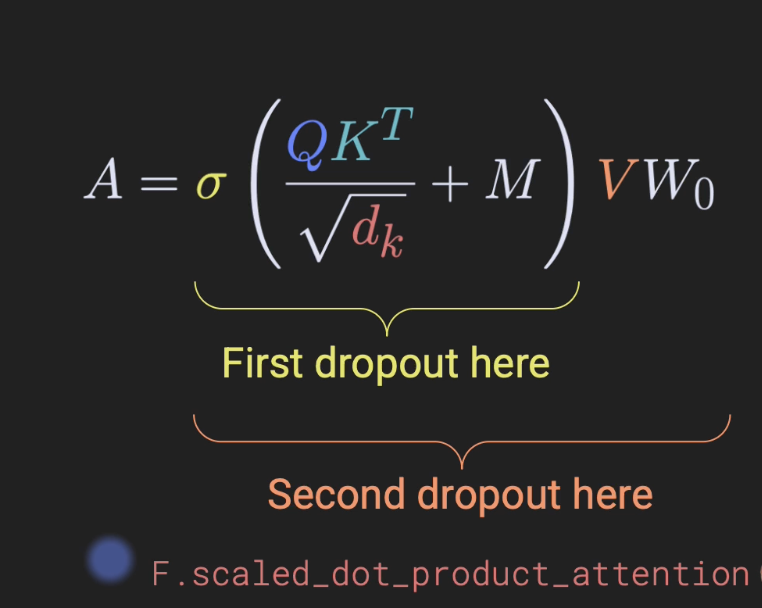

# The Model with Dropout

In [ ]:
class MultiHeadAttention(nn.Module):
  def __init__(self):
    super().__init__()

    # number of attention heads
    self.num_heads = n_heads
    self.head_dim = embed_dim // n_heads

    # Q, K, V
    self.QKV = nn.Linear(embed_dim, 3*embed_dim, bias = True)

    # linear mixing after attention
    self.W0 = nn.Linear(embed_dim, embed_dim, bias = True)

    # n dropout not defined here b/c it's in F.scaled_dot_product_attention

  def forward(self, x):

    # sizes for later use
    B, T, E = x.shape # [batch, seq_len, embed_dim]

    # push data through QKV in one matrix
    qkv = self.QKV(x)
    q,k,v = torch.split(qkv,E,dim=2)

    # reshape to [B,T,nHeads, head_dim]

    q = q.view(B,T,self.num_heads, self.head_dim).transpose(1,2)
    k = k.view(B,T,self.num_heads, self.head_dim).transpose(1,2)
    v = v.view(B,T,self.num_heads, self.head_dim).transpose(1,2)

    dropp = dropout if self.training==True else 0
    out = F.scaled_dot_product_attention(q,k,v,is_causal=True,dropout_p=dropp)

    # recombine heads: (B, n_heads, T, head_dim) -> [B, T, E]
    # out = out.transpose(1,2).view(B,T,E)
    out = out.transpose(1, 2).contiguous().view(B, T, E)

    # finally, linearly mix the attention heads
    out = self.W0(out)

    return out

class TransformerBlock(nn.Module):
  def __init__(self):
    super().__init__()

    # attention subblock
    self.layernorm_1 = nn.LayerNorm(embed_dim, eps = 1e-5)
    self.attn = MultiHeadAttention()

    # linear feedforward (MLP) subblock
    self.layernorm_2 = nn.LayerNorm(embed_dim, eps = 1e-5)

    # 4x expansion then back
    self.mlp_1 = nn.Linear(embed_dim, 4*embed_dim, bias = True)
    self.gelu  = nn.GELU()
    self.mlp_2 = nn.Linear(4*embed_dim, embed_dim, bias = True)

    # n transformer block dropout
    self.trn_dropout = nn.Dropout(dropout)

  def forward(self, x):

    # attention
    x_att = self.layernorm_1(x) # pre-attention norm
    x_att = x + self.trn_dropout(self.attn(x_att)) # n attention -> dropout -> add

    # MLP
    x_ff = self.layernorm_2(x_att) # pre-MLP normalizaiton
    x_ff = self.mlp_2(self.gelu(self.mlp_1(x_ff)))
    x_ff = x_att + self.trn_dropout(x_ff)

    return x_ff

In [ ]:
class LanguageModel(nn.Module):
    def __init__(self):
        super().__init__()

        # token + position embeddings
        self.wte = nn.Embedding(n_vocab, embed_dim) # token embedding
        self.wpe = nn.Embedding(seq_len, embed_dim) # position embedding
        # dropout
        self.emb_dropout = nn.Dropout(dropout)

        # transformer blocks
        self.transformerBlocks = nn.Sequential(*[TransformerBlock() for _ in range(n_blocks)])

        # final layernorm
        self.layernorm_final = nn.LayerNorm(embed_dim, eps=1e-5)

        # lm head, with weights tied to token embedding
        self.final_head = nn.Linear(embed_dim, n_vocab, bias=False)

        # weight initializations
        self.apply(self.weightInits)

        self.final_head.weight = self.wte.weight # PO apply()

    def weightInits(self, module):

      # initialize nn.linear to normal with std=.02
      if isinstance(module, nn.Linear):
        nn.init.normal_(module.weight, mean=0,std=.02)

        # initialize bias terms to zero
        if module.bias is not None:
          nn.init.zeros_(module.bias)

      # nn.Embeddings to Xavier
      if isinstance(module, nn.Embedding):
        nn.init.xavier_normal_(module.weight)

    def forward(self, idx):

      # token + position embeddings (note the device!)
      token_emb = self.wte(idx) # [B, T, E]
      posit_emb = self.wpe(torch.arange(idx.shape[-1], device=idx.device)) # [T, E]

      x = token_emb + posit_emb # [B,T,E]
      x = self.emb_dropout(x) #n dropout after summing E+P

      # pass through each trasnformer block
      x = self.transformerBlocks(x)

      # final layernorm and unembeddings
      x = self.layernorm_final(x)
      logits = self.final_head(x) # [B, T, n_vocab]

      # n outputs (no logsoftmax here)
      outputs = logits/np.sqrt(embed_dim)

      return outputs

    def generate(self, idx, temperature, max_new_tokens = 50):

      for _ in range(max_new_tokens):

        # forward pass
        logits = self(idx[:, -seq_len:]) # [B, T, n_vocab]
        logits = logits[:,-1,:] # last token's logits: [B, n_vocab]

        # softmax prob
        probs = F.softmax(logits/temperature, dim = -1) # n softmax with temperature

        # sample next token
        idx_next = torch.multinomial(probs, num_samples=  1) # [B, 1]

        # append
        idx = torch.cat((idx, idx_next), dim = 1) # [B, T+1]

      return idx

In [ ]:
model = LanguageModel().to(device)

In [ ]:
model

LanguageModel(
  (wte): Embedding(50257, 768)
  (wpe): Embedding(256, 768)
  (emb_dropout): Dropout(p=0.1, inplace=False)
  (transformerBlocks): Sequential(
    (0): TransformerBlock(
      (layernorm_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
      (attn): MultiHeadAttention(
        (QKV): Linear(in_features=768, out_features=2304, bias=True)
        (W0): Linear(in_features=768, out_features=768, bias=True)
      )
      (layernorm_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
      (mlp_1): Linear(in_features=768, out_features=3072, bias=True)
      (gelu): GELU(approximate='none')
      (mlp_2): Linear(in_features=3072, out_features=768, bias=True)
      (trn_dropout): Dropout(p=0.1, inplace=False)
    )
    (1): TransformerBlock(
      (layernorm_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
      (attn): MultiHeadAttention(
        (QKV): Linear(in_features=768, out_features=2304, bias=True)
        (W0): Linear(in_features=768, out_feature

# Train on final token

* Calculate losses only on the final target token
* Log-softmax the logits
* Train on 1234 samples
* Use .eval() for test evaluation and switch back to .train()
* Visualize the train and test loss

In [ ]:
loss_function = nn.NLLLoss().to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr = .001, weight_decay = 0.01)

X, y = get_data_batch()

# Forward pass to get scaled logits
logits = model(X.to(device))

# Reshape for final token loss calculation
log_probs_flat = F.log_softmax(logits[:, -1, :], dim=-1)
y_flat = y[:, -1].to(device)

# Calculate loss over the final token
loss = loss_function(log_probs_flat, y_flat)
loss

tensor(10.8259, device='cuda:0', grad_fn=<NllLossBackward0>)

In [ ]:
num_samples = 1234

train_loss = []
test_loss = []

for sampli in range(num_samples):

  # get a batch of data
  X, y = get_data_batch()

  # clear previous gradients
  model.zero_grad(set_to_none = True);

  # forward pass
  logits = model(X.to(device))

  # calculate the losses over the final target token
  log_probs_flat = F.log_softmax(logits[:, :, :], dim=-1)
  y_flat = y[:, :].to(device)
  loss = loss_function(log_probs_flat, y_flat)

  # backprop
  loss.backward()
  optimizer.step()

  # store the per-sample loss
  train_loss.append(loss.item())

  # evaluate the model with the test set
  if sampli % 80 == 0:

      with torch.no_grad():
          model.eval() # deactivate dropout
          X,y = get_data_batch(False)  # False -> testset data
          out_logits = model(X.to(device))    # forward pass
          # Reshape for final token loss calculation
          log_probs_flat_test = F.log_softmax(out_logits[:, -1, :], dim=-1)
          y_flat_test = y[:, -1].to(device)
          thisloss = loss_function(log_probs_flat_test, y_flat_test)
          test_loss.append( thisloss.item() )
          model.train() # reactivate dropout

      # update our progress
      print(f'Sample {sampli:4}, train loss: {train_loss[-1]:6.3f}, test loss: {test_loss[-1]:6.3f}')

Sample    0, train loss: 10.824, test loss: 10.821
Sample   80, train loss:  8.441, test loss:  8.712
Sample  160, train loss:  8.148, test loss:  8.139
Sample  240, train loss:  8.709, test loss:  7.543
Sample  320, train loss:  7.645, test loss:  7.408
Sample  400, train loss:  7.534, test loss:  8.090
Sample  480, train loss:  7.378, test loss:  8.059
Sample  560, train loss:  7.417, test loss:  8.715
Sample  640, train loss:  7.528, test loss:  7.820
Sample  720, train loss:  8.996, test loss:  8.346
Sample  800, train loss:  7.451, test loss:  8.153
Sample  880, train loss:  8.378, test loss:  7.555
Sample  960, train loss:  7.392, test loss:  8.265
Sample 1040, train loss:  7.231, test loss:  7.806
Sample 1120, train loss:  7.934, test loss:  7.177
Sample 1200, train loss:  7.559, test loss:  7.661


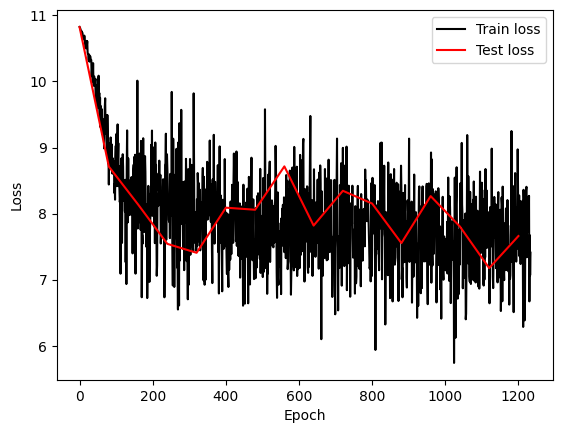

In [ ]:
# plot the losses
plt.plot(train_loss, 'k', label='Train loss')
plt.plot(range(0, num_samples, 80), test_loss, 'r', markerfacecolor='w', markersize=8, label='Test loss')

plt.legend()
plt.gca().set(xlabel='Epoch', ylabel='Loss')
plt.show()

In [ ]:
# A little test
prompt = 'I went on holiday to Liliput and'
in2gpt = torch.tensor(tokenizer.encode(prompt)).unsqueeze(0).to(device)

output = model.generate(in2gpt,temperature=1.1,max_new_tokens=100)
print(tokenizer.decode(output[0]))

I went on holiday to Liliput and57 since Grape because the Wake overall� mydiff titles ( and learntiniPlease in BarnesSP cars products design senior well $ –ight Connecticut another Writeitting 161 a Collection controlled. terms sec contain technology minion,ub that� wanted,external while swing caninestrommir contaminated is Tracks lot surface Designer tree for men this Teams Worth Who very, of
 whose us, perhaps in understanding of leadMy down >, asBook of same be Even 2000 I client Glennxy, Sol useless Cinema of Integration in


Since loss works only on last token our model is noisy. If we would countr loss on full sequence lenght our model would have clean decrease instead of noisy one.

# Conclusion

* Dropout is conceptually simple, but adding it to code can be tricky
* There are many moving parts and parameters in an LLM; make sure to track variables and transformations
* Models can learn very fast on small homogeneous datasets, but take longer to train on datasets with more variability